# Data distribution experiments

# My Custom Experiments

In the previous sections I have attempted to re-produce experiments from Gatmiry et al. In the following sections, I will implement several experiments that apply different assumptions and test the theoretical bounds of this paper. These were not written in the original paper.

In [1]:
# Imports and setup

import torch
from matplotlib import pyplot as plt
import os
import numpy as np

from linear_transformer import DataMode
from experiments_helper import (
    run_experiment_suite,
    compute_loss_dict,
    compute_dist_dict,
    plot_loss_curves,
    plot_parameter_matrices,
    plot_dist_to_identity,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

In [2]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, alg, normal_data_mode, N, d, n_head, B, var,
    max_iters, hist_stride, stride, TEST_SEED,
)

print(f'Running on device: {device}.')

Running on device: cuda.


# Different Data Distributions

Train the shared-weight looped transformers from the first experiment independently on each configured data mode, then evaluate each set of checkpoints on an independently sampled test batch from that same mode. The seeds, loop counts, optimization settings, and model setup match the first experiment; the gamma shape parameter comes from the problem-parameter cell.

In [3]:
# Add data mode as an independent experiment configuration.
gamma_data_mode_low_shape = DataMode("gamma", gamma_shape=0.1, gamma_scale=1)
gamma_data_mode_high_shape = DataMode("gamma", gamma_shape=5, gamma_scale=1)
t_distribution_mode = DataMode("t", t_degrees_freedom=5)

seeds = [0, 1, 2]
loop_counts = [1, 2, 5]
model_types = ['looped']
context_lengths = [N]
data_modes = [normal_data_mode, gamma_data_mode_low_shape, gamma_data_mode_high_shape, t_distribution_mode]
iterations = np.arange(0, max_iters, stride)

In [ ]:
gamma_fig_dir = os.path.join('figures', 'data_mode_comparison')
os.makedirs(gamma_fig_dir, exist_ok=True)

gamma_history_file = os.path.join(
    cur_dir, f'data_modes_normal_gamma_N{N}_d{d}_histories.pth')
gamma_results_file = os.path.join(
    cur_dir, f'data_modes_normal_gamma_N{N}_d{d}_results.pth')

gamma_hist_dict = run_experiment_suite(
    seeds=seeds,
    n_layers_loops=loop_counts,
    model_types=model_types,
    filename=gamma_history_file,
    context_lengths=context_lengths,
    data_modes=data_modes,
    freeze_p=True,  # [P-FIX] paper's P = [[0, 0], [0, 1]]
)

gamma_loss_dict = {
    test_data_mode: compute_loss_dict(
        gamma_hist_dict,
        test_seed=TEST_SEED,
        data_mode=test_data_mode,
    )
    for test_data_mode in data_modes
}
# Parameter distances depend on the trained checkpoints, not on the test data mode.
gamma_dist_dict = compute_dist_dict(
    gamma_hist_dict, iterations, n_head, hist_stride=hist_stride)


Run 1/36: seed=0, count=1, type=looped, N=20, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear, freeze_p=True, learn_u=False
iter 0 | Loss: 5.274337291717529 | time: 0.23362040519714355 | gradnorm: 4.807002067565918
iter 1 | Loss: 5.061816692352295 | time: 0.004959583282470703 | gradnorm: 4.562503337860107
iter 2 | Loss: 4.949411869049072 | time: 0.004036426544189453 | gradnorm: 4.421471118927002
iter 3 | Loss: 4.871385097503662 | time: 0.003402233123779297 | gradnorm: 4.326864242553711
iter 4 | Loss: 5.046316623687744 | time: 0.003407001495361328 | gradnorm: 4.587100028991699
iter 100 | Loss: 4.091986656188965 | time: 0.003352642059326172 | gradnorm: 4.001680374145508
iter 200 | Loss: 3.2562427520751953 | time: 0.003348112106323242 | gradnorm: 3.403515100479126
iter 300 | Loss: 2.613921642303467 | time: 0.0033600330352783203 | gradnorm: 2.83896803855896
iter 400 | Loss: 2.113097667694092 | time: 0.0032880306243896484 |

In [5]:
torch.save({
    'config': {
        'N': N, 'd': d, 'B': B, 'n_head': n_head,
        'data_modes': data_modes,
        'alg': alg, 'lr': lr, 'var': var,
        'max_iters': max_iters, 'hist_stride': hist_stride, 'stride': stride,
        'seeds': seeds, 'loop_counts': loop_counts,
        'model_types': model_types, 'test_seed': TEST_SEED,
    },
    'history_file': gamma_history_file,
    'hist_dict': gamma_hist_dict,
    'loss_dict_by_test_mode': gamma_loss_dict,
    'distance_dict': gamma_dist_dict,
    'iterations': iterations,
}, gamma_results_file)
print(f'Saved data-mode experiment results to {gamma_results_file}')

Saved data-mode experiment results to log/data_modes_normal_gamma_N20_d5_results.pth


In [4]:
# Load the saved data-mode results instead of retraining. Run the two setup cells
# above first, then this one (skip the training and torch.save cells).
# weights_only=False is needed because the file stores DataMode objects and numpy arrays.
gamma_results_file = os.path.join(
    cur_dir, f'data_modes_normal_gamma_N{N}_d{d}_results.pth')
gamma_results = torch.load(gamma_results_file, map_location='cpu', weights_only=False)

gamma_config = gamma_results['config']
data_modes = gamma_config['data_modes']
seeds = gamma_config['seeds']
loop_counts = gamma_config['loop_counts']
model_types = gamma_config['model_types']
context_lengths = [gamma_config['N']]

gamma_history_file = gamma_results['history_file']
gamma_hist_dict = gamma_results['hist_dict']
gamma_loss_dict = gamma_results['loss_dict_by_test_mode']
gamma_dist_dict = gamma_results['distance_dict']
iterations = gamma_results['iterations']

gamma_fig_dir = os.path.join('figures', 'data_mode_comparison')
os.makedirs(gamma_fig_dir, exist_ok=True)

print(f'Loaded {len(gamma_hist_dict)} runs from {gamma_results_file}')
print('Config:', {k: v for k, v in gamma_config.items() if k != 'data_modes'})
print('Data modes:', [_data_mode.name for _data_mode in data_modes])

Loaded 36 runs from log/data_modes_normal_gamma_N20_d5_results.pth
Config: {'N': 20, 'd': 5, 'B': 4000, 'n_head': 1, 'alg': 'adam', 'lr': 0.001, 'var': 0.0001, 'max_iters': 10000, 'hist_stride': 1, 'stride': 100, 'seeds': [0, 1, 2], 'loop_counts': [1, 2, 5], 'model_types': ['looped'], 'test_seed': 99}
Data modes: ['normal', 'gamma', 'gamma', 't']


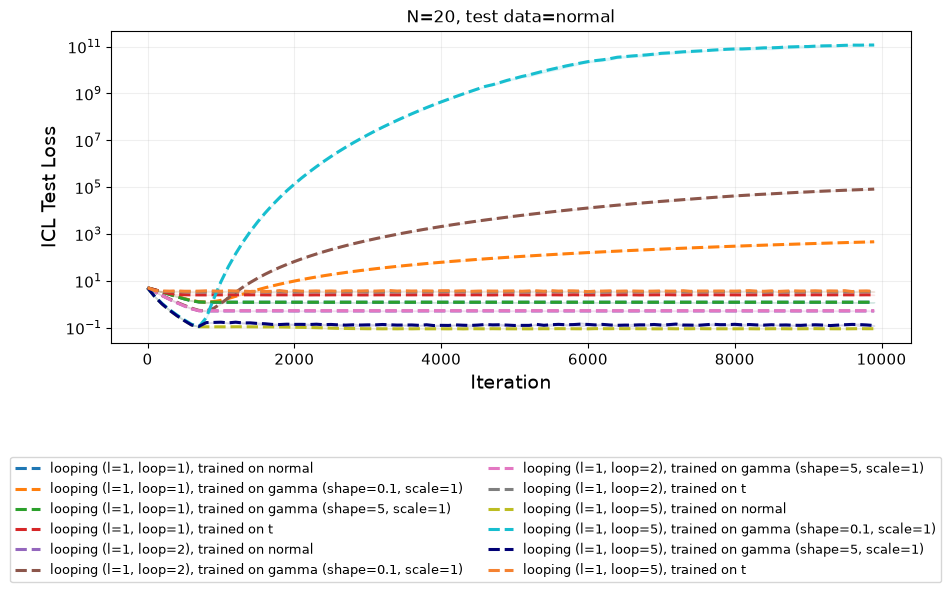

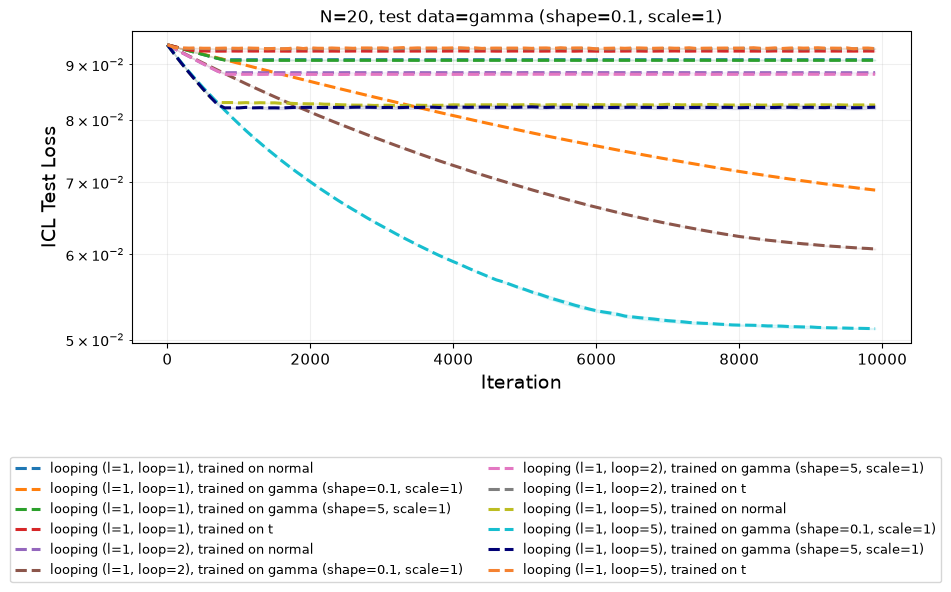

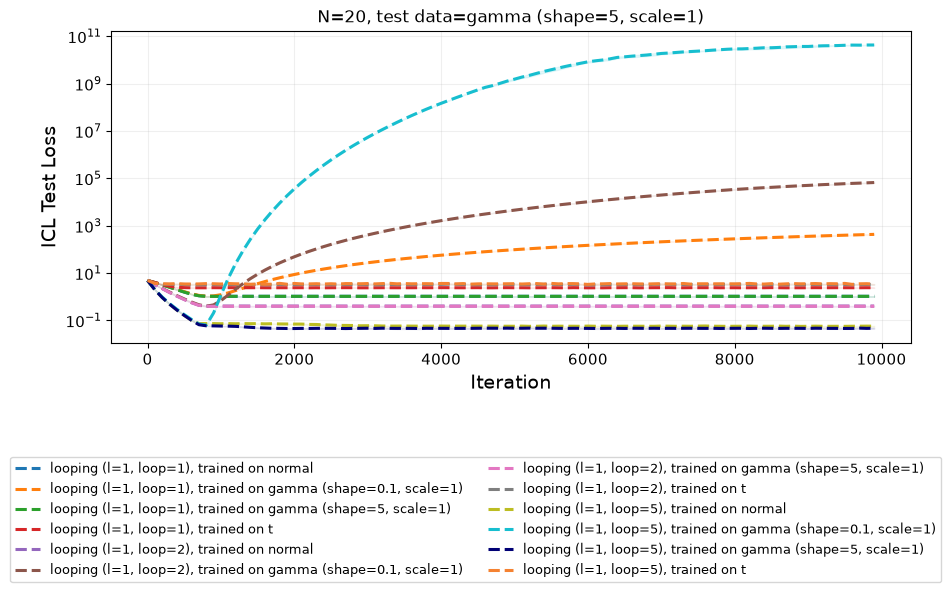

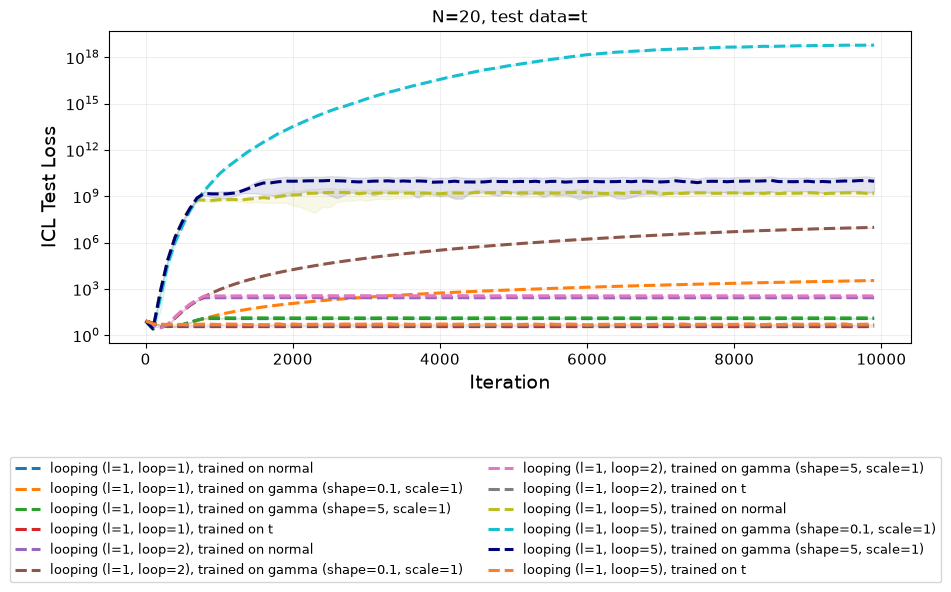

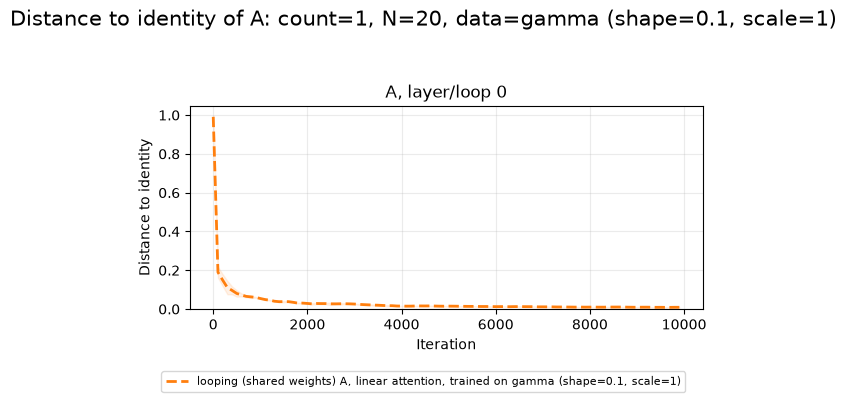

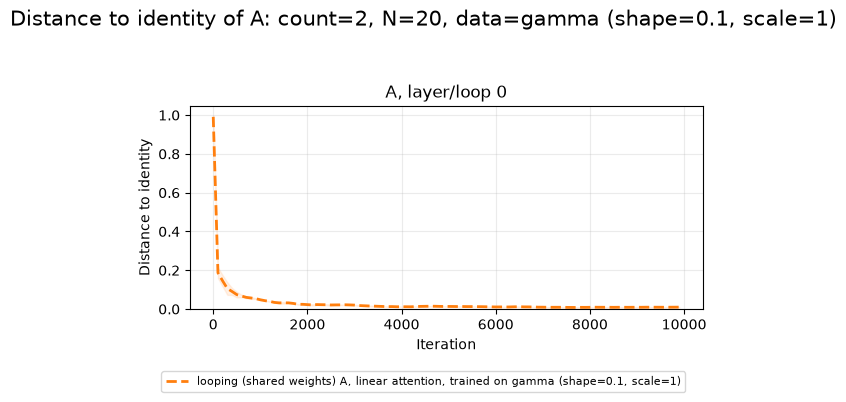

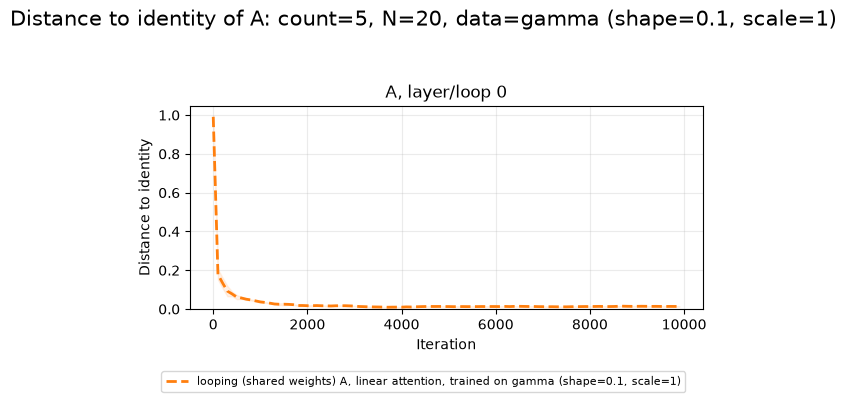

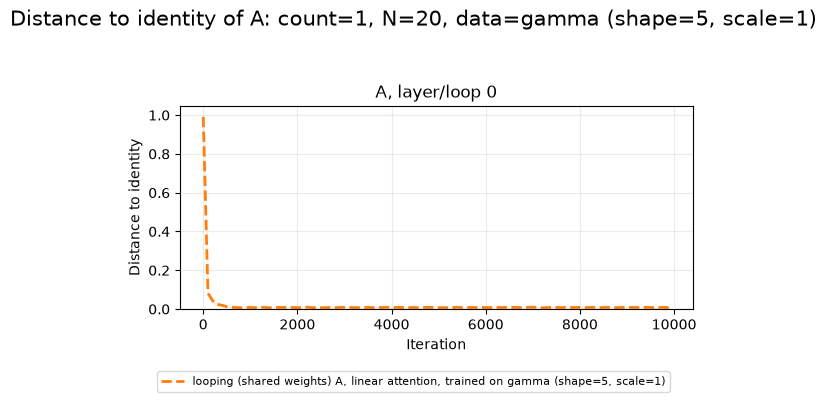

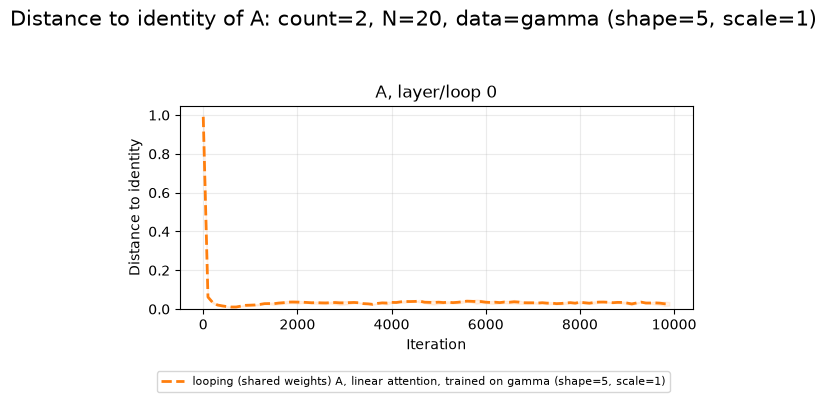

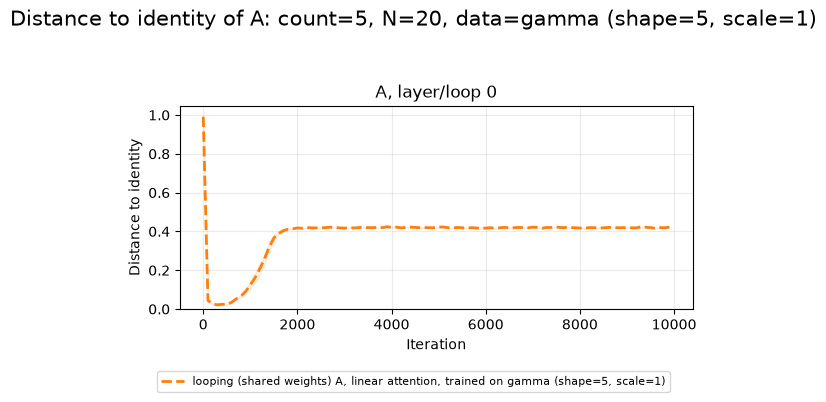

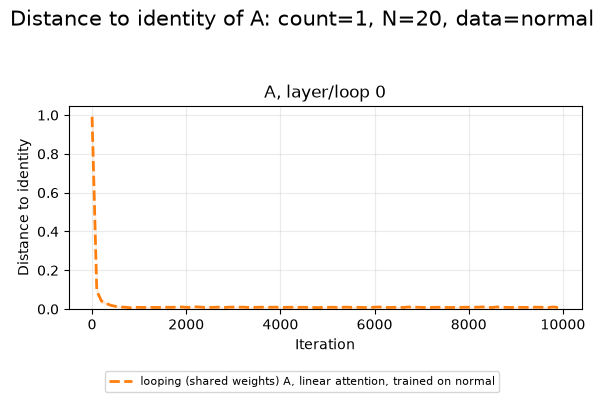

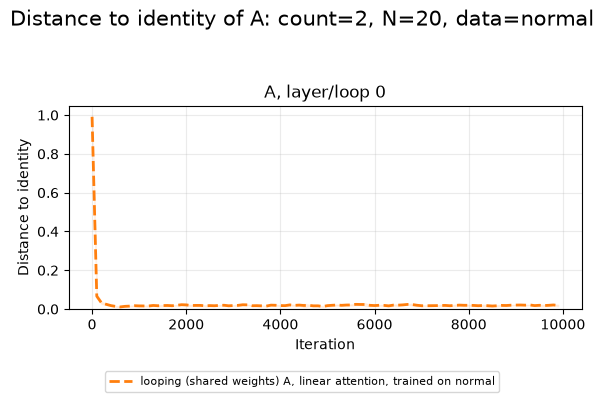

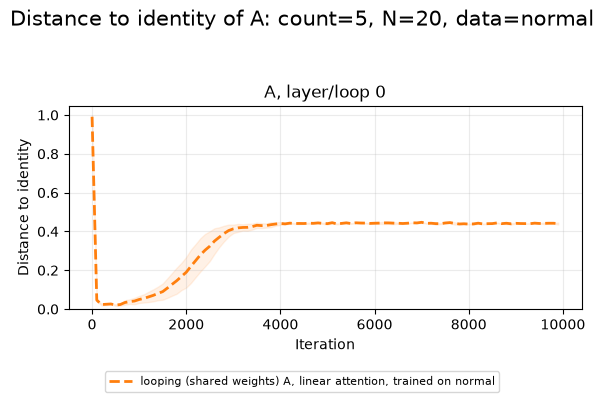

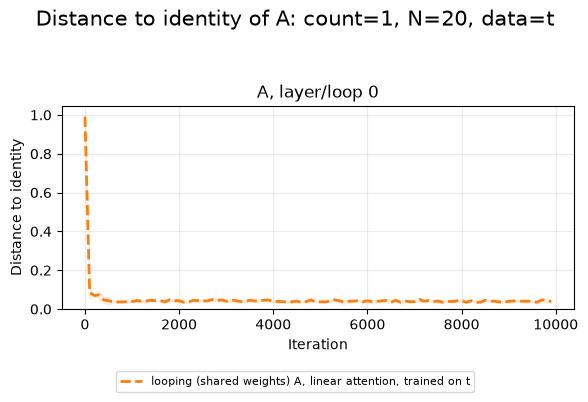

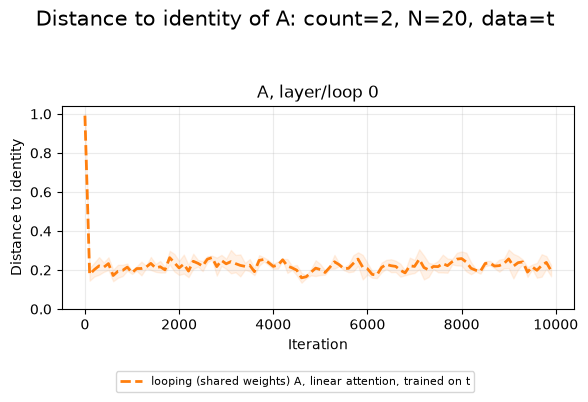

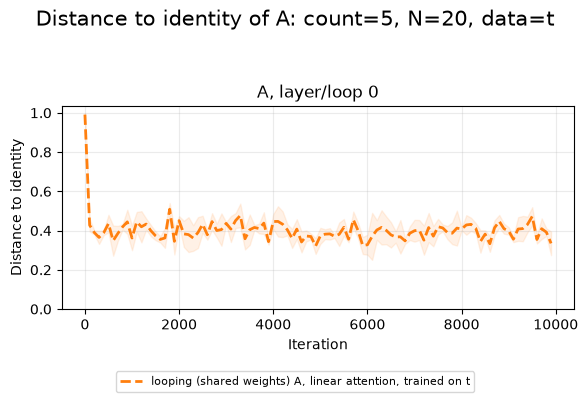

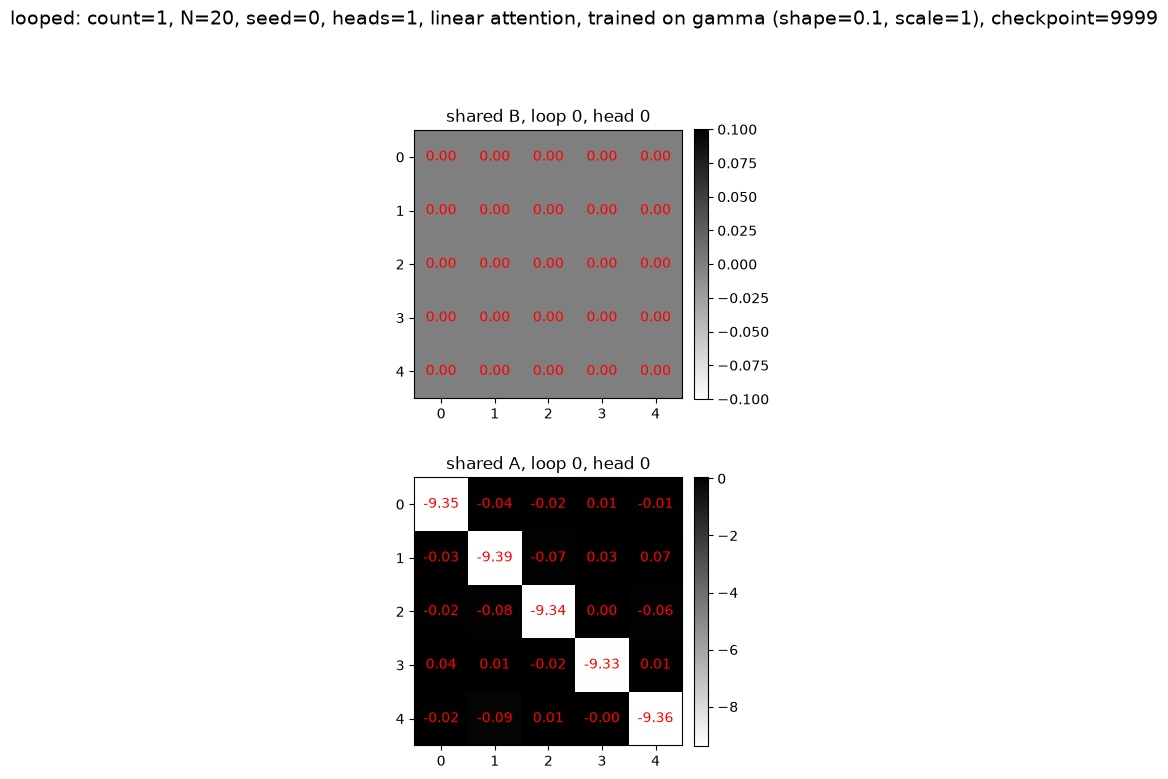

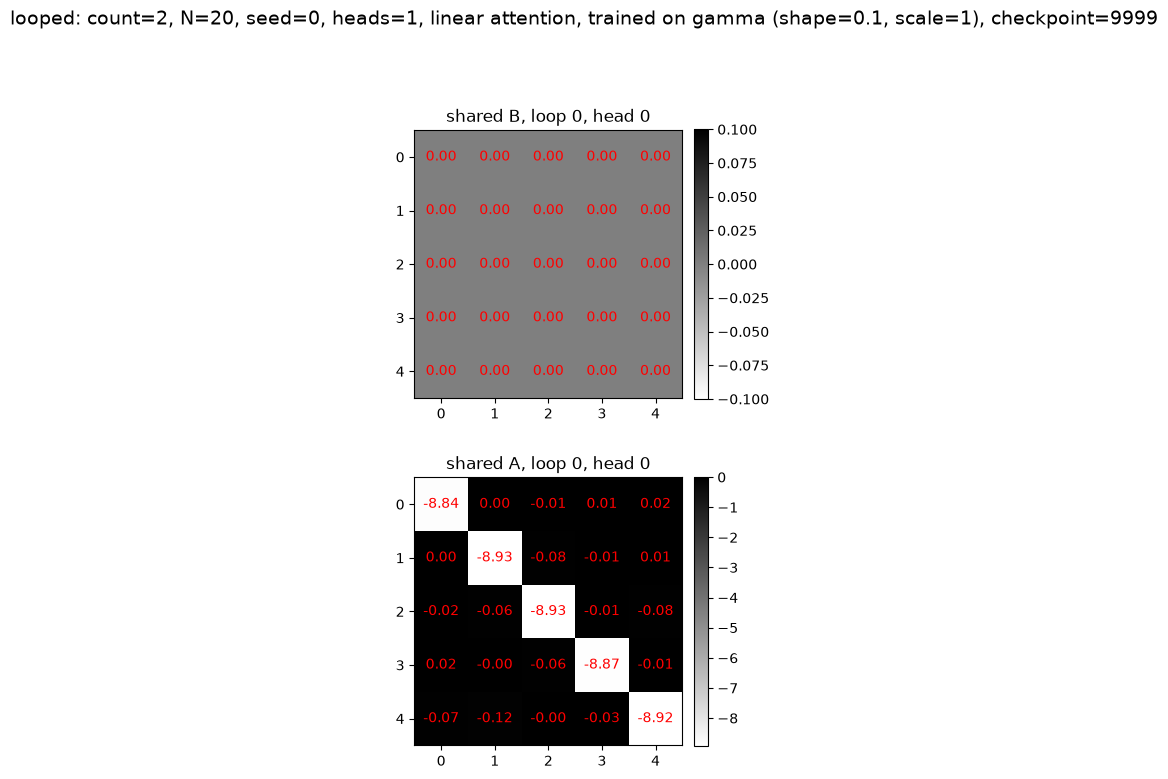

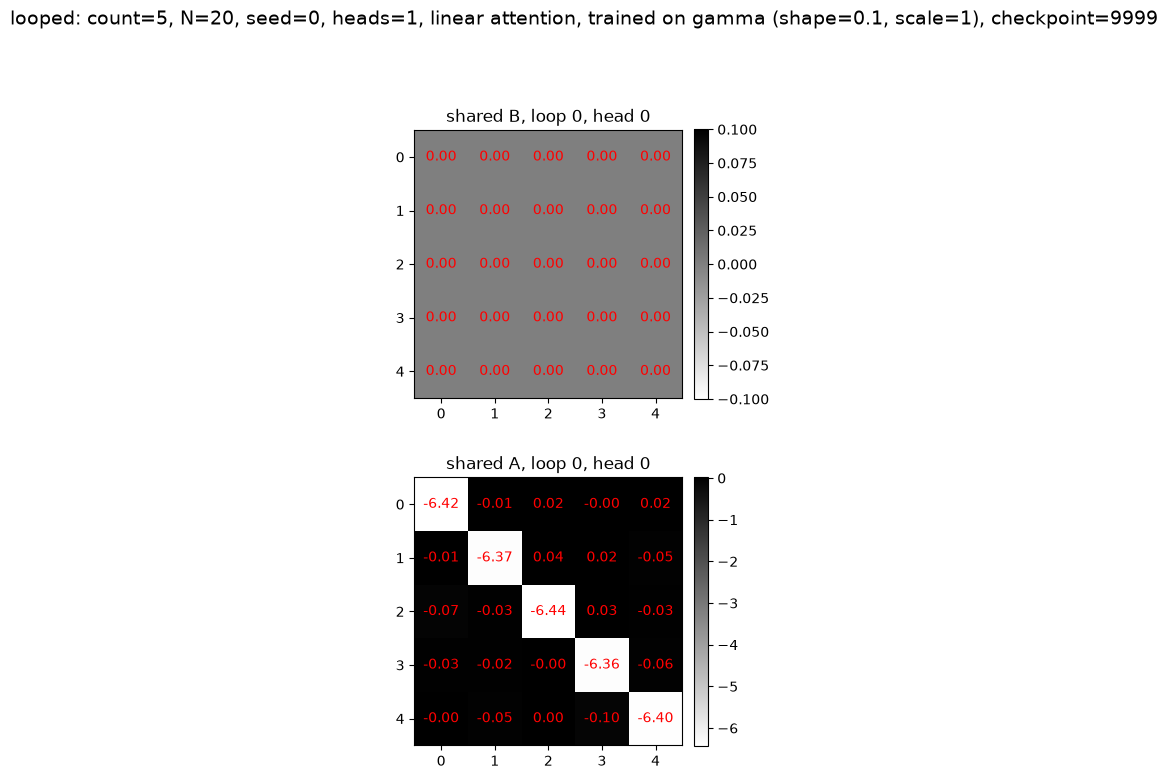

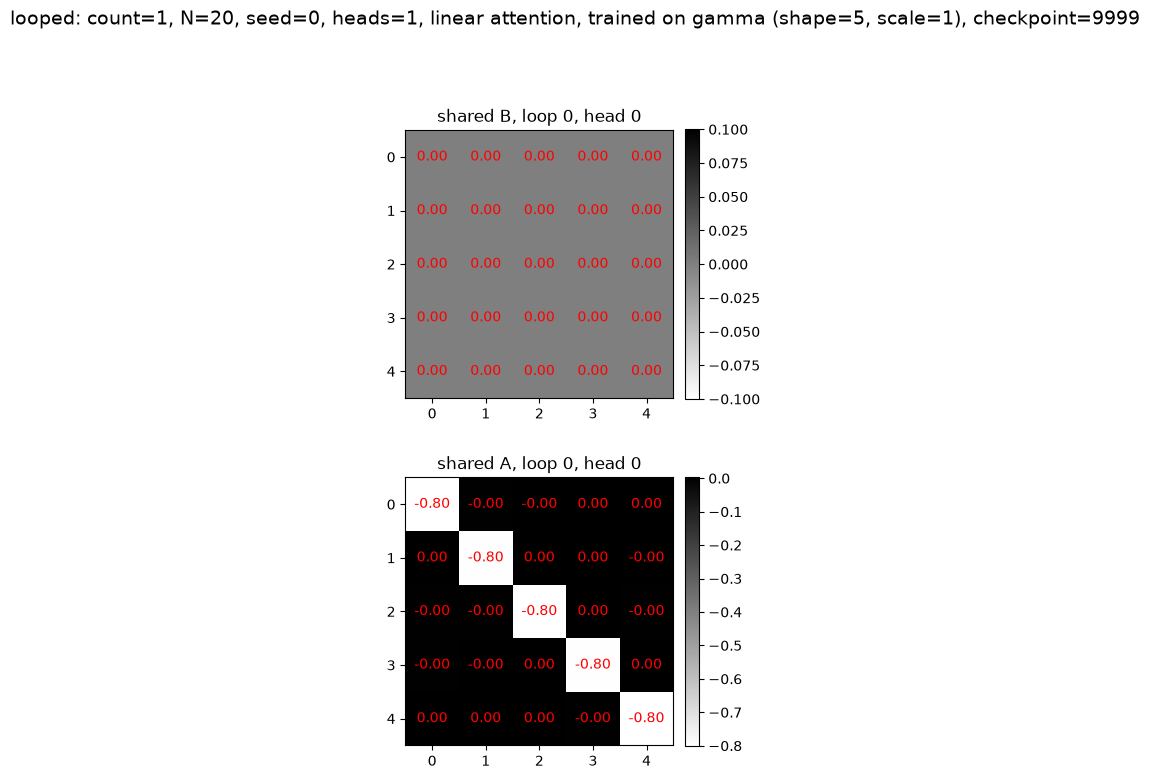

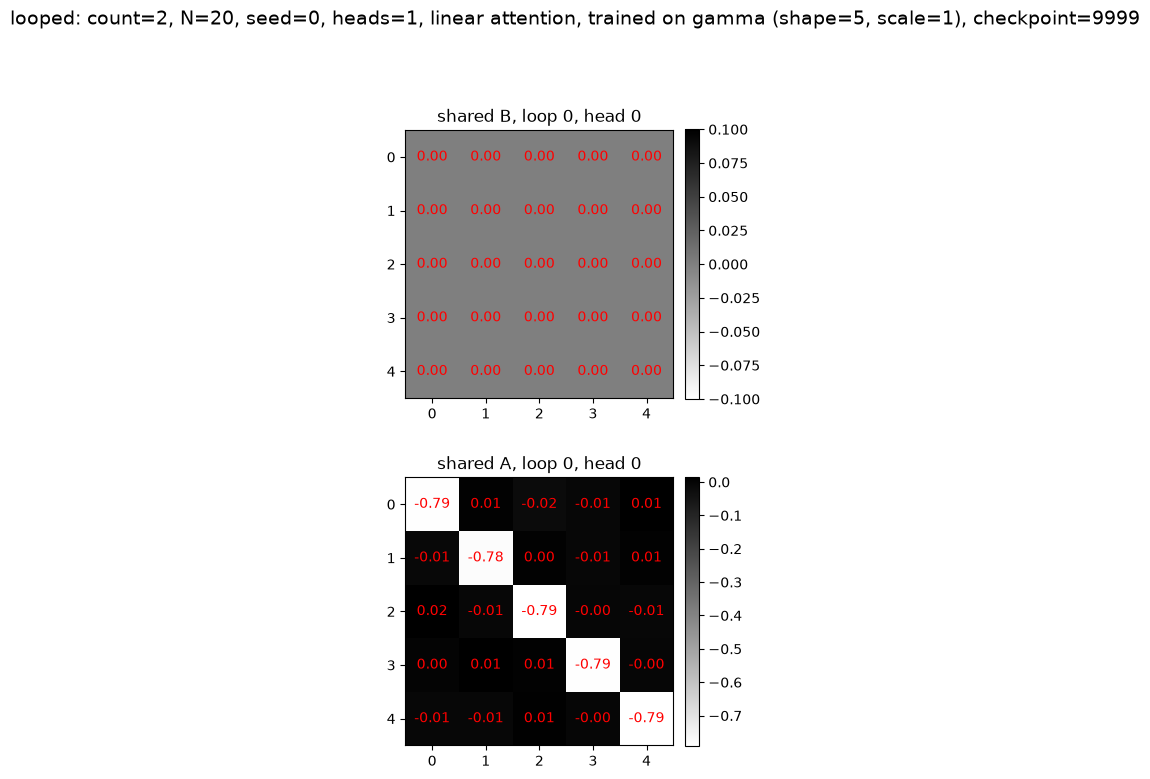

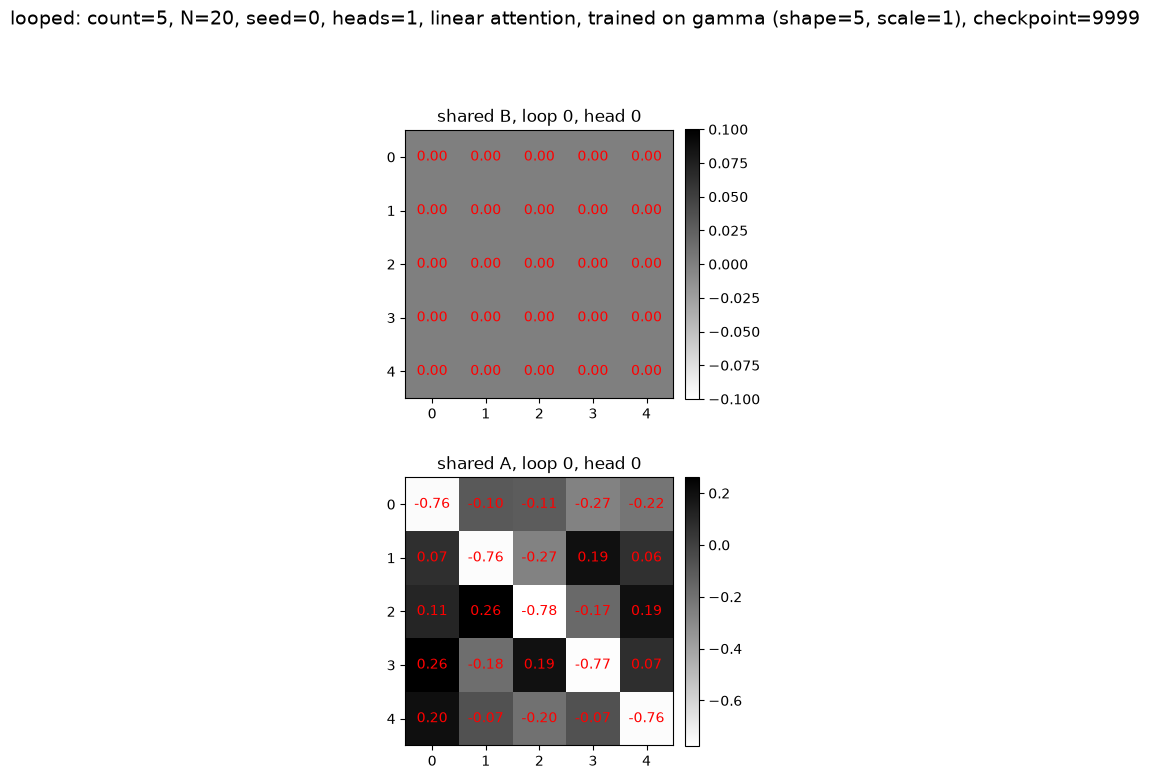

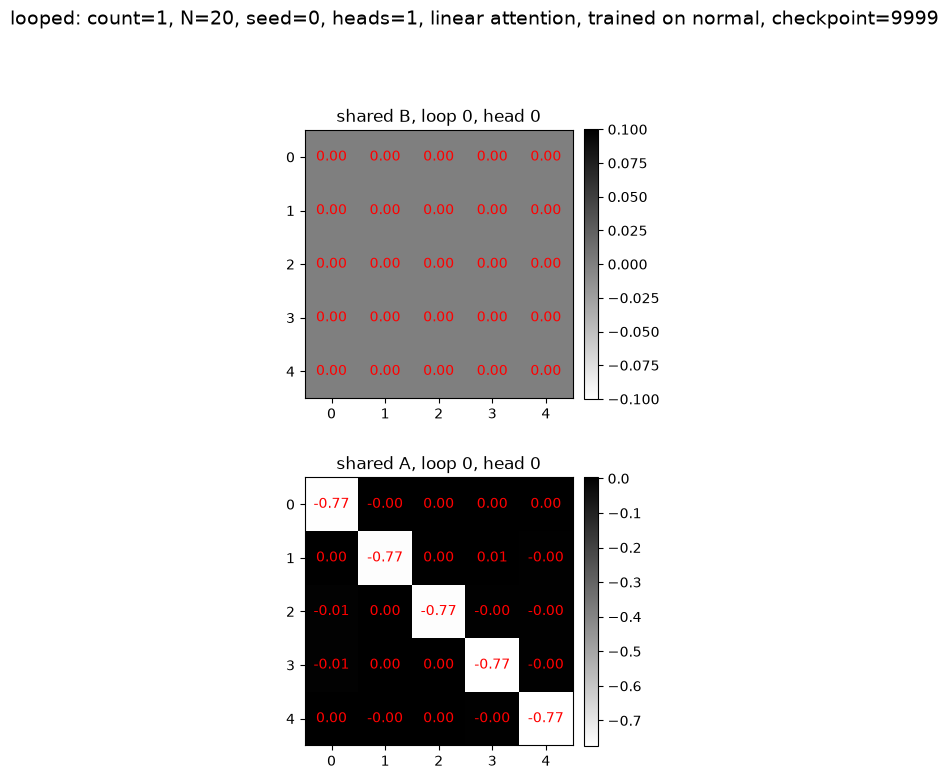

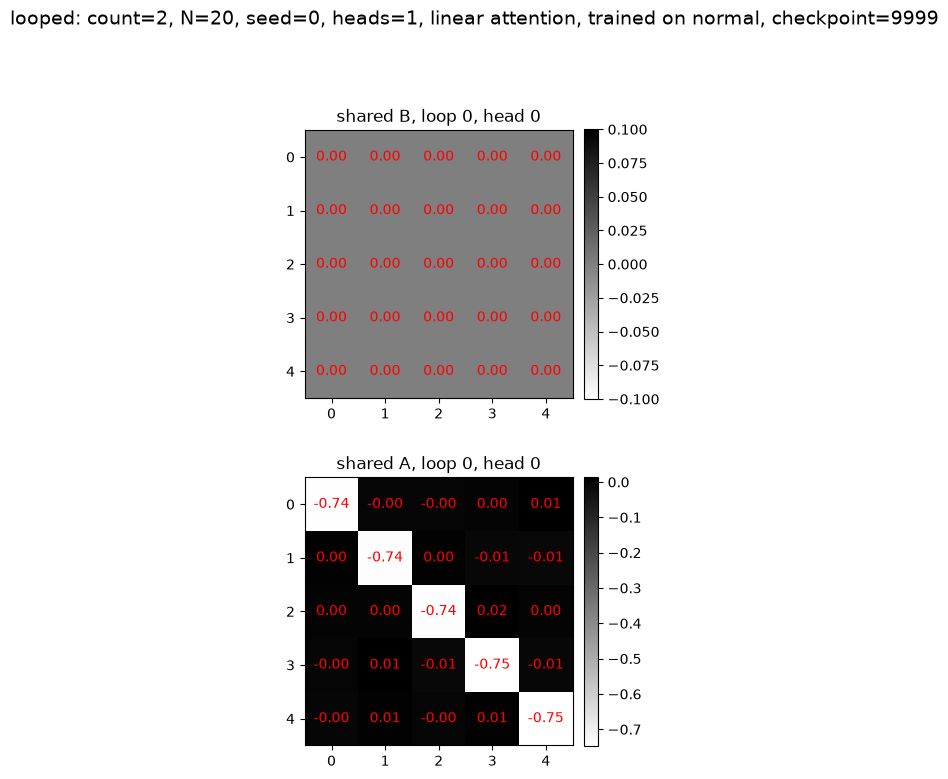

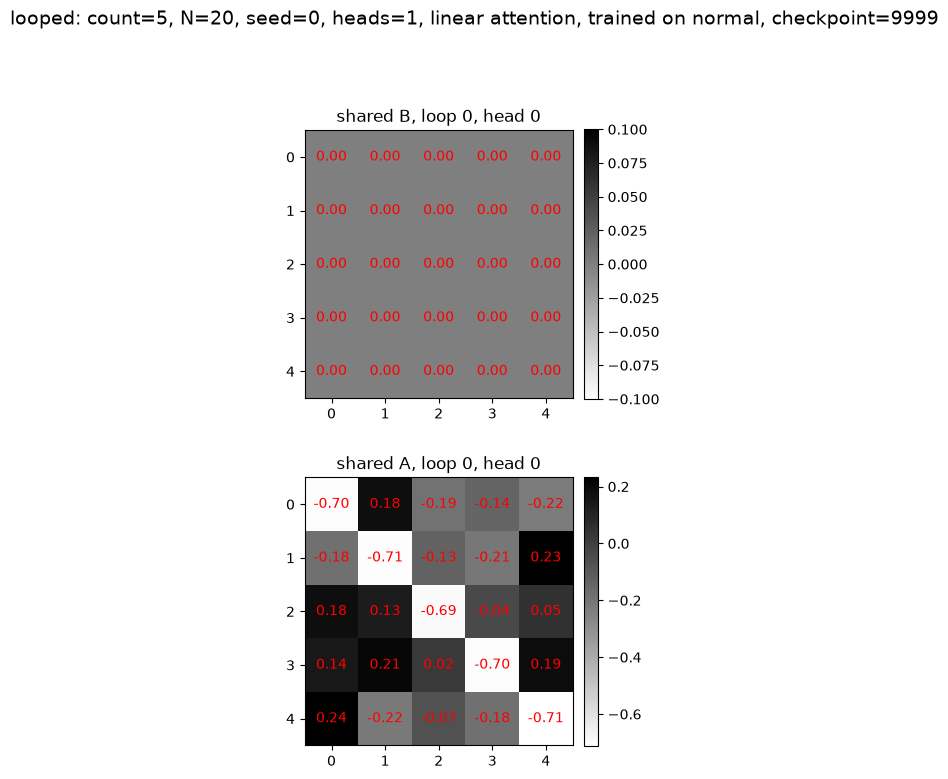

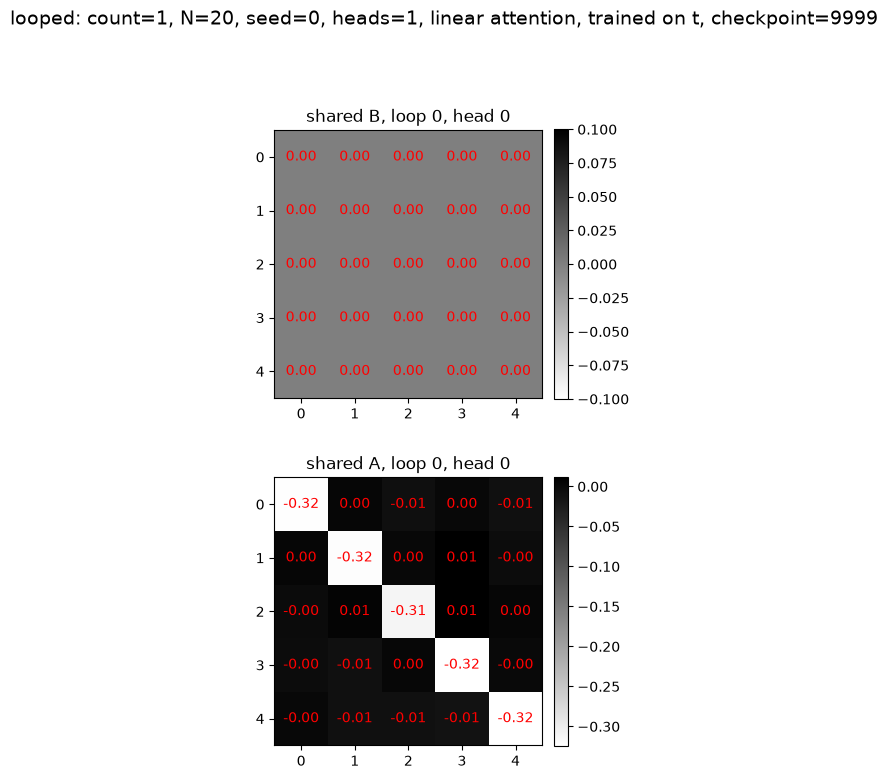

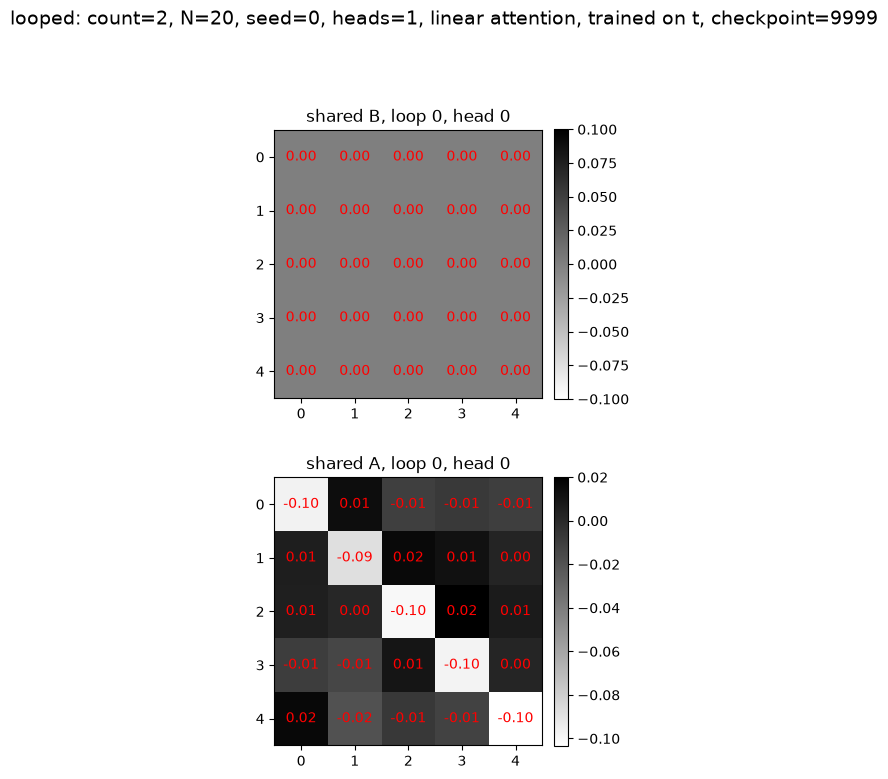

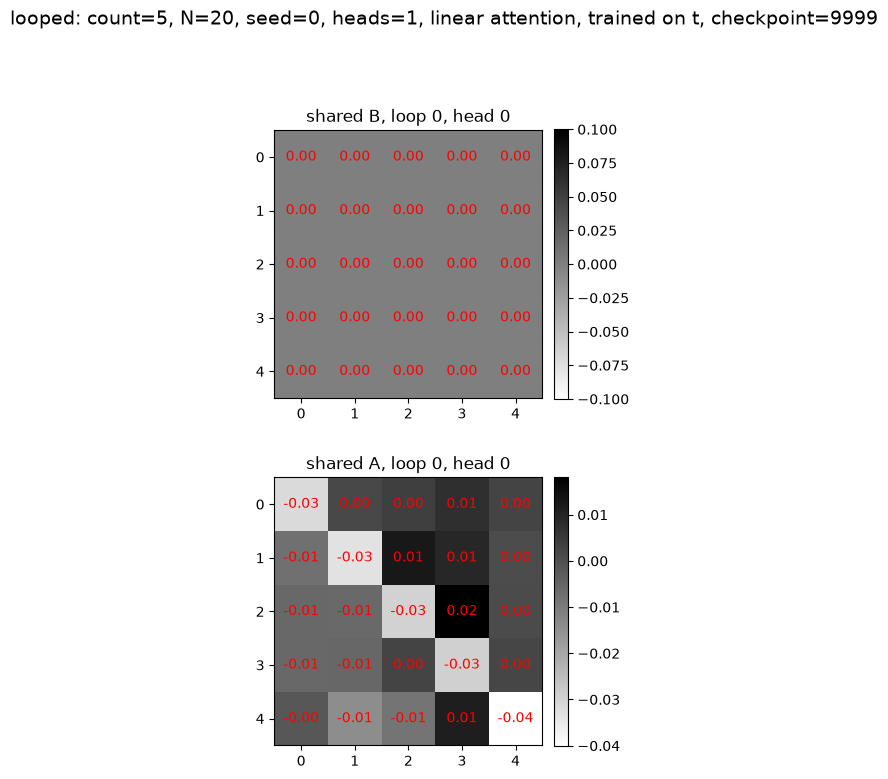

In [5]:
for test_data_mode, loss_dict in gamma_loss_dict.items():
    plot_loss_curves(
        loss_dict, loop_counts, model_types, iterations,
        fig_dir=gamma_fig_dir, filename='data_mode_test_loss.pdf',
        test_data_mode=test_data_mode,
        labels=["distribution"]
    )
plot_dist_to_identity(
    gamma_dist_dict, loop_counts, iterations, fig_dir=gamma_fig_dir,
)
plot_parameter_matrices(
    gamma_hist_dict, seeds[0], loop_counts, model_types, n_head,
    hist_stride=hist_stride, fig_dir=gamma_fig_dir,
)


# Non-Linear Distribution Test

Train the shared-weight looped transformers independently on normal, ReLU-generated, and MLP-generated data. This mirrors the different-distribution experiment: the same seeds, loop counts, optimization settings, and plots are reused to check whether the training converges and to display the learned parameter trajectories.


In [7]:
relu_data_mode = DataMode("relu")
mlp_data_mode = DataMode("mlp")

seeds = [0, 1, 2]
loop_counts = [2, 5, 10]
model_types = ['looped']
context_lengths = [N]
nonlinear_data_modes = [normal_data_mode, relu_data_mode, mlp_data_mode]
iterations = np.arange(0, max_iters, stride)

nonlinear_fig_dir = os.path.join('figures', 'nonlinear_data_mode_comparison')
os.makedirs(nonlinear_fig_dir, exist_ok=True)

nonlinear_history_file = os.path.join(
    cur_dir, f'nonlinear_data_modes_N{N}_d{d}_histories.pth')
nonlinear_results_file = os.path.join(
    cur_dir, f'nonlinear_data_modes_N{N}_d{d}_results.pth')

nonlinear_hist_dict = run_experiment_suite(
    seeds=seeds,
    n_layers_loops=loop_counts,
    model_types=model_types,
    filename=nonlinear_history_file,
    context_lengths=context_lengths,
    data_modes=nonlinear_data_modes,
    freeze_p=True,  # [P-FIX] paper's P = [[0, 0], [0, 1]]
)

nonlinear_loss_dict = {
    test_data_mode: compute_loss_dict(
        nonlinear_hist_dict,
        test_seed=TEST_SEED,
        data_mode=test_data_mode,
    )
    for test_data_mode in nonlinear_data_modes
}
nonlinear_dist_dict = compute_dist_dict(
    nonlinear_hist_dict, iterations, n_head, hist_stride=hist_stride)

torch.save({
    'config': {
        'N': N, 'd': d, 'B': B, 'n_head': n_head,
        'data_modes': nonlinear_data_modes,
        'alg': alg, 'lr': lr, 'var': var,
        'max_iters': max_iters, 'hist_stride': hist_stride, 'stride': stride,
        'seeds': seeds, 'loop_counts': loop_counts,
        'model_types': model_types, 'test_seed': TEST_SEED,
    },
    'history_file': nonlinear_history_file,
    'hist_dict': nonlinear_hist_dict,
    'loss_dict_by_test_mode': nonlinear_loss_dict,
    'distance_dict': nonlinear_dist_dict,
    'iterations': iterations,
}, nonlinear_results_file)
print(f'Saved non-linear data-mode experiment results to {nonlinear_results_file}')

# TODO: Look into Ahn et al (or the empirical paper they reference) and see how this changes when implementing non-linear regressions (I think this can be done with unconstrained B)

Run 1/27: seed=0, count=2, type=looped, N=20, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear, freeze_p=True, learn_u=False
iter 0 | Loss: 5.274796962738037 | time: 0.0070209503173828125 | gradnorm: 9.615306854248047
iter 1 | Loss: 5.0525431632995605 | time: 0.006032228469848633 | gradnorm: 9.10390567779541
iter 2 | Loss: 4.928557395935059 | time: 0.005928516387939453 | gradnorm: 8.7908296585083
iter 3 | Loss: 4.843500137329102 | time: 0.006103992462158203 | gradnorm: 8.58931827545166
iter 4 | Loss: 5.005734443664551 | time: 0.006463527679443359 | gradnorm: 9.079337120056152
iter 100 | Loss: 3.3704450130462646 | time: 0.005179643630981445 | gradnorm: 6.131927490234375
iter 200 | Loss: 2.2515196800231934 | time: 0.005228519439697266 | gradnorm: 3.968468189239502
iter 300 | Loss: 1.5689407587051392 | time: 0.005213499069213867 | gradnorm: 2.5794482231140137
iter 400 | Loss: 1.1575946807861328 | time: 0.00503230094909668 

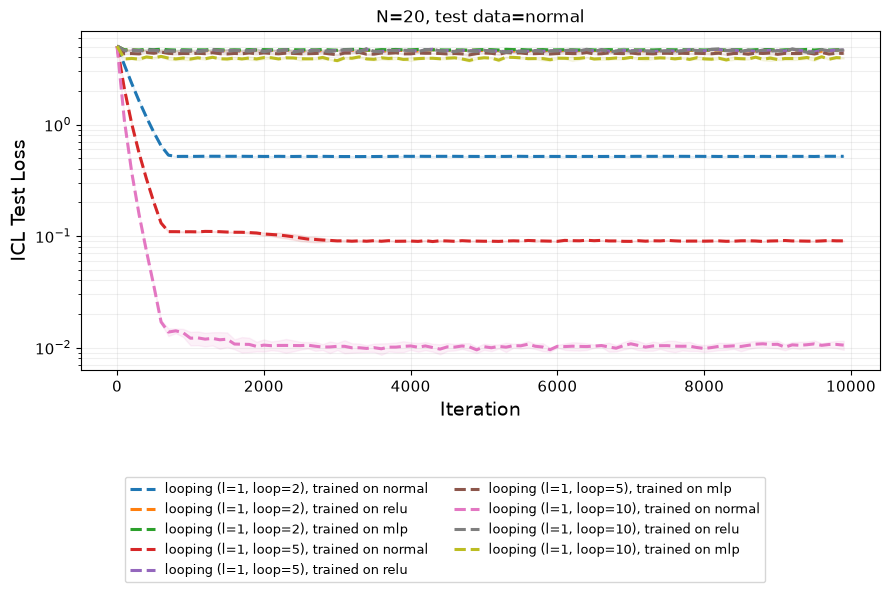

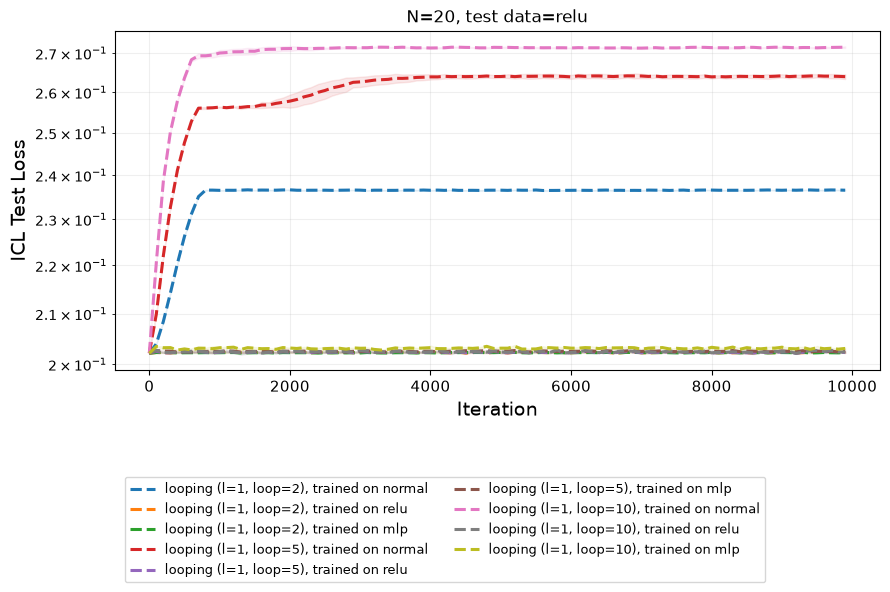

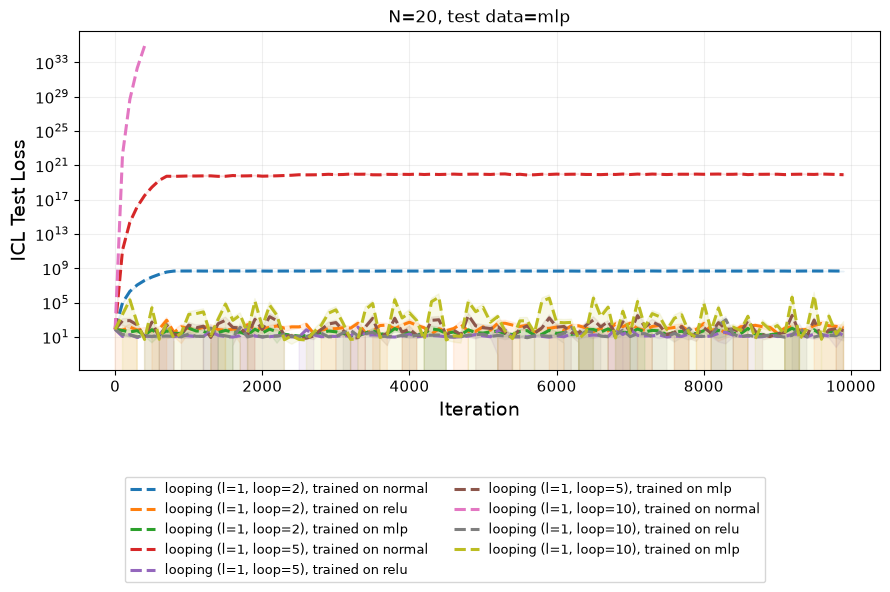

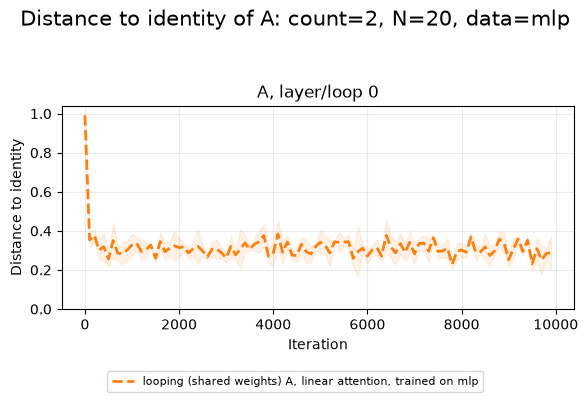

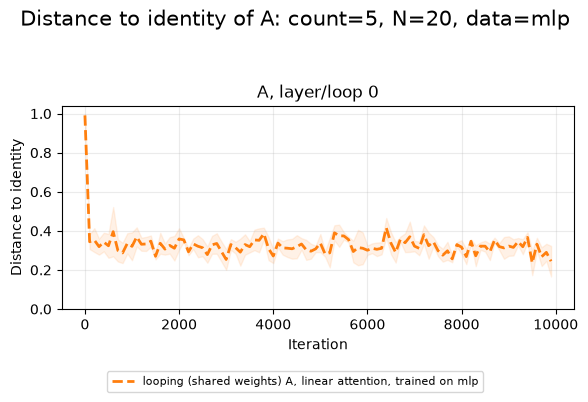

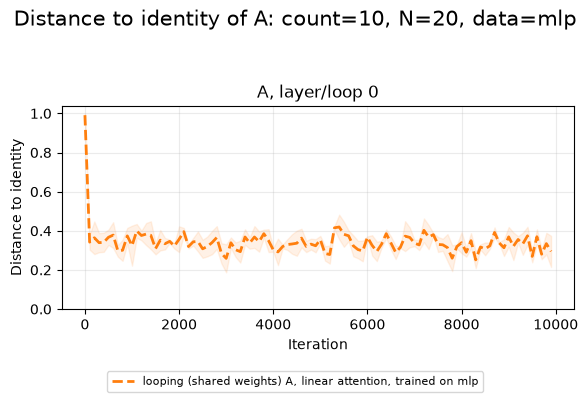

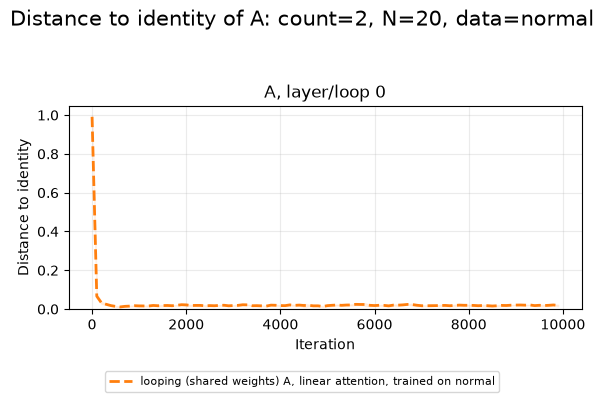

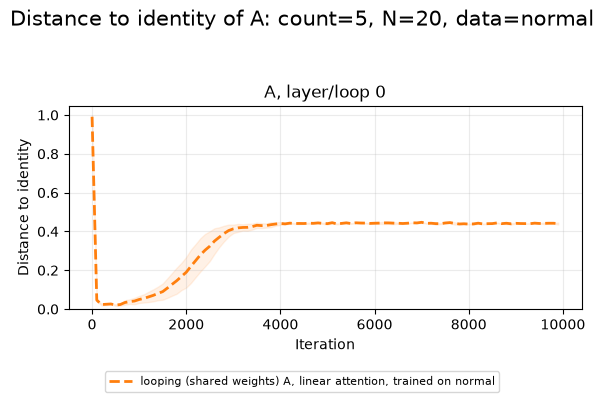

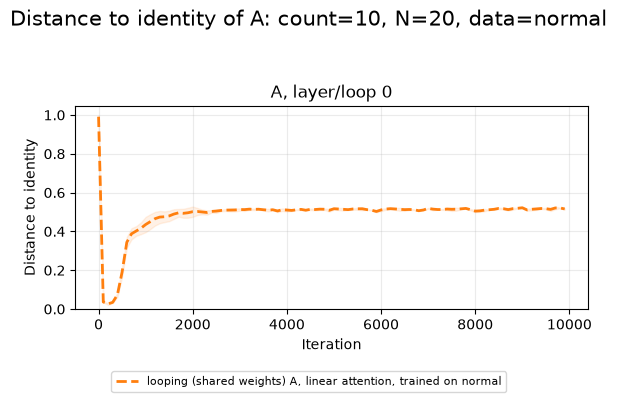

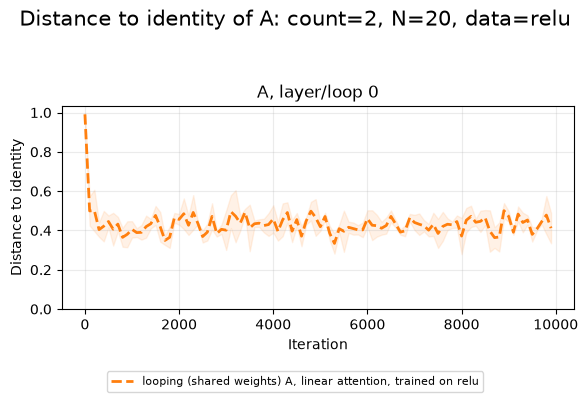

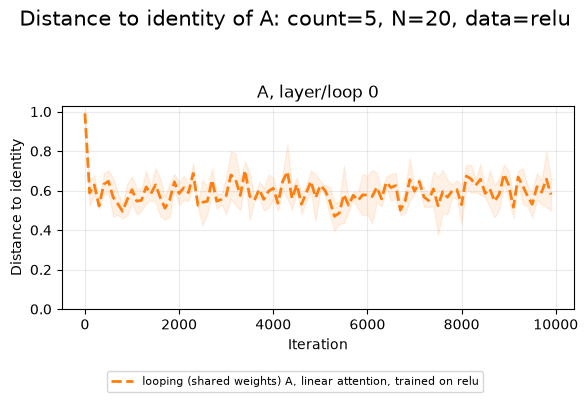

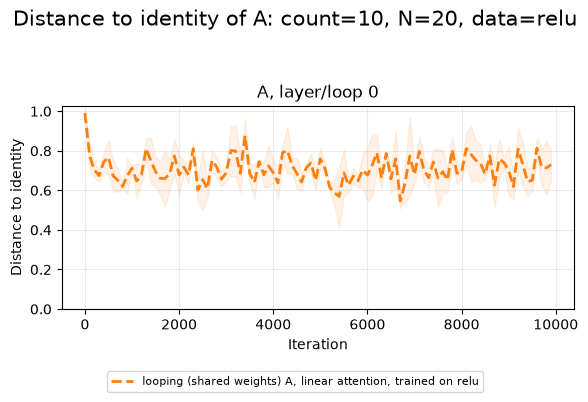

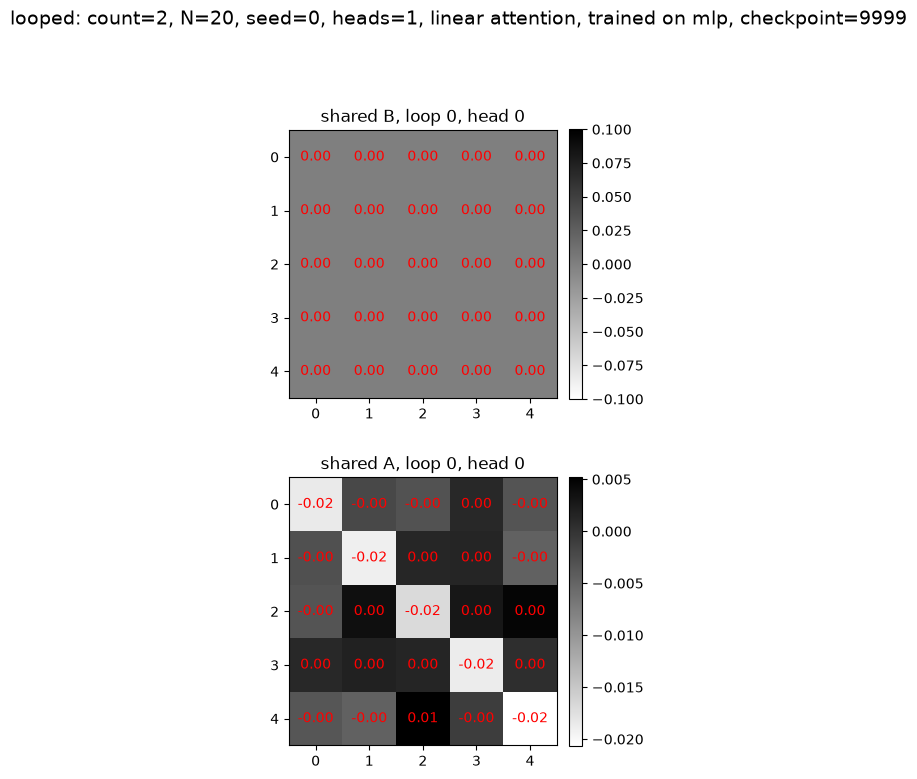

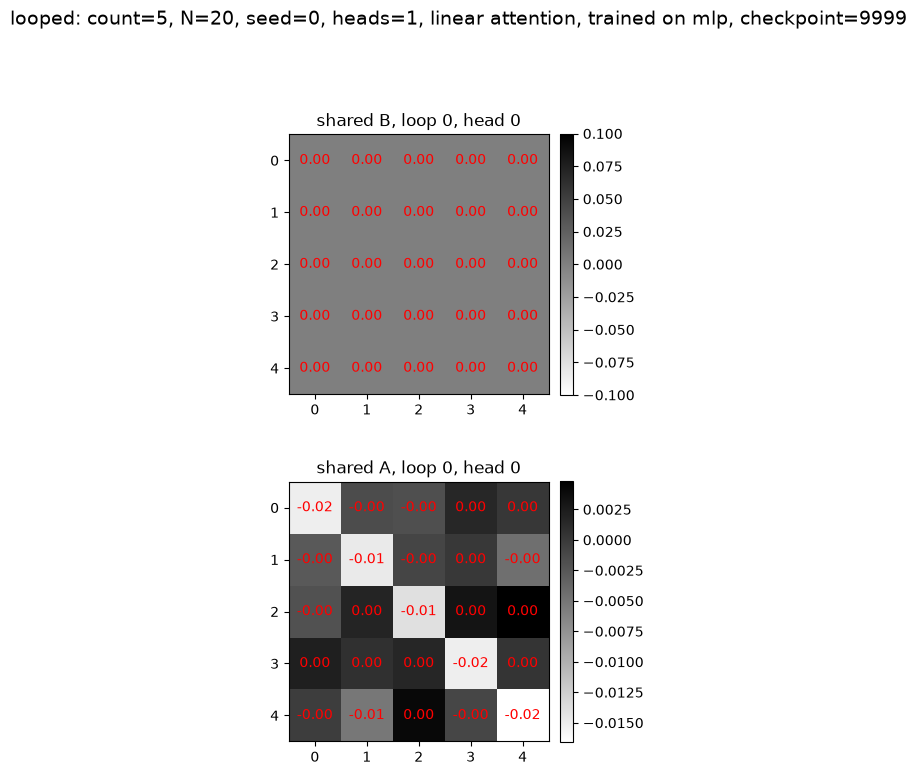

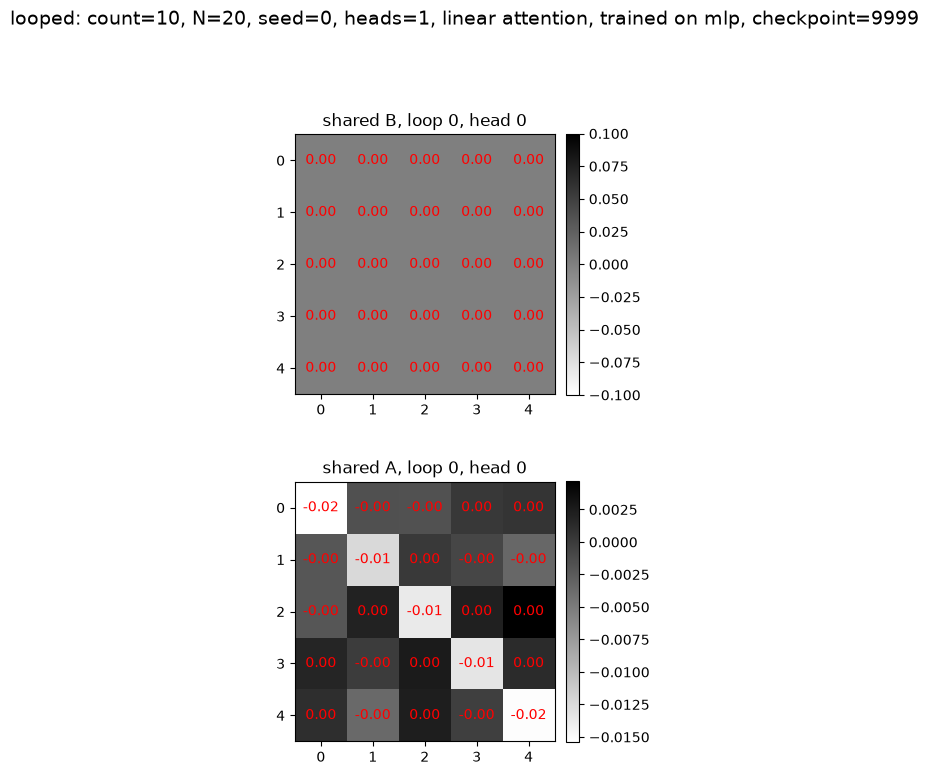

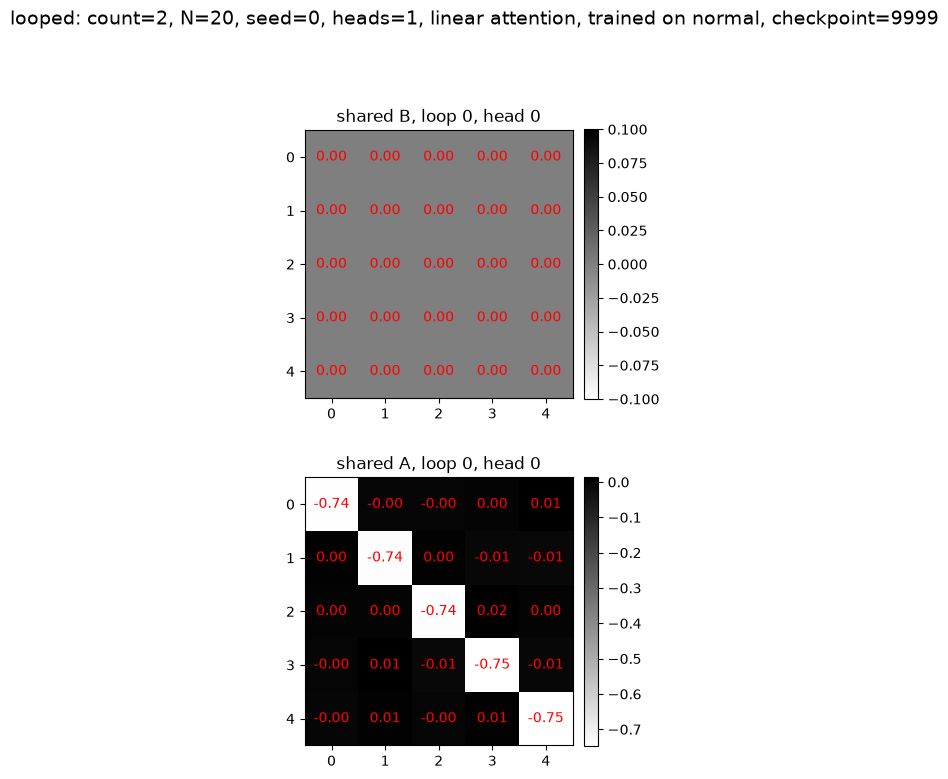

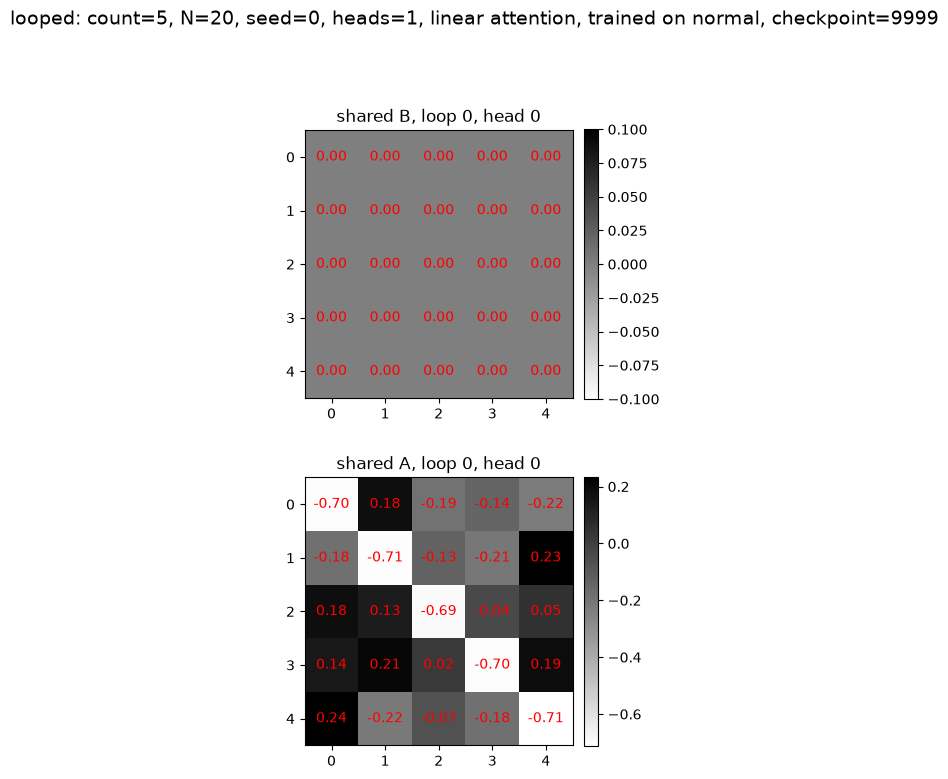

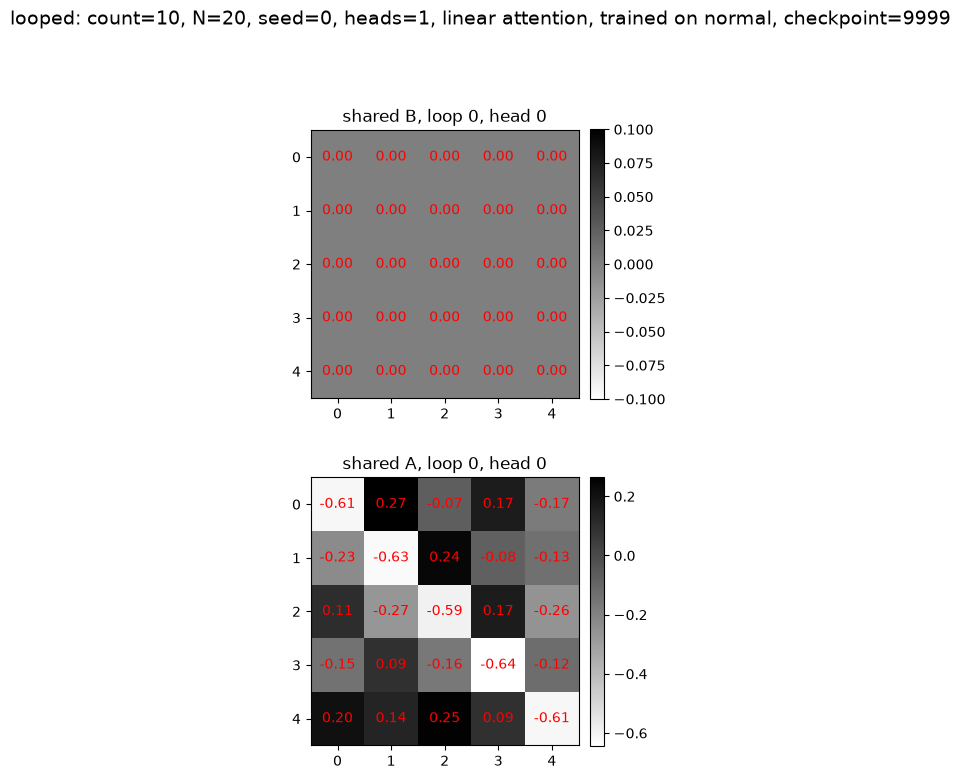

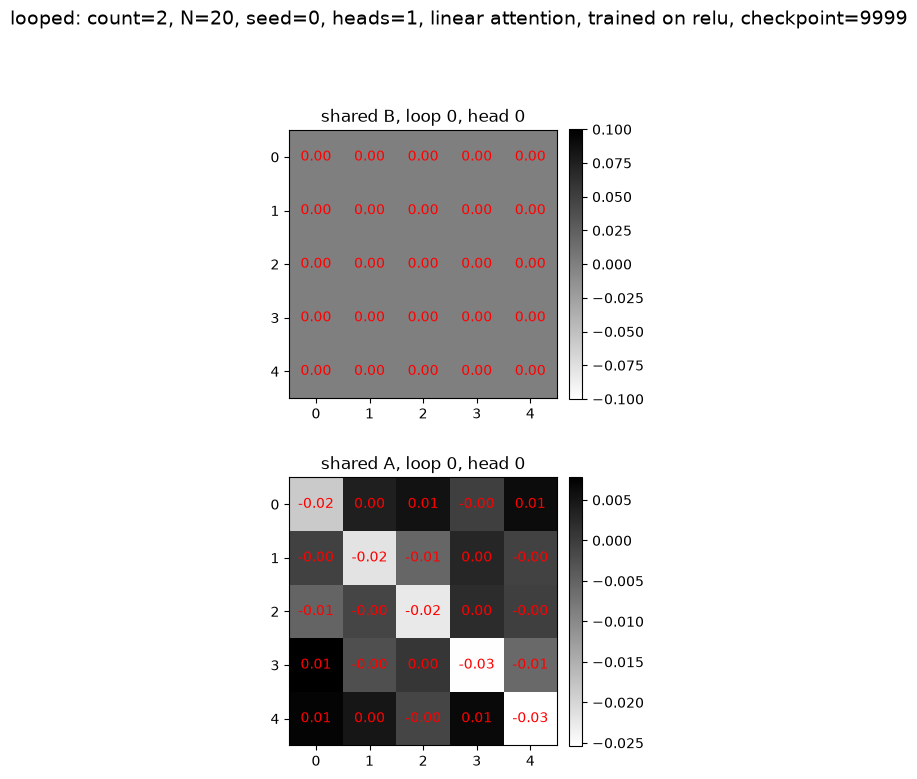

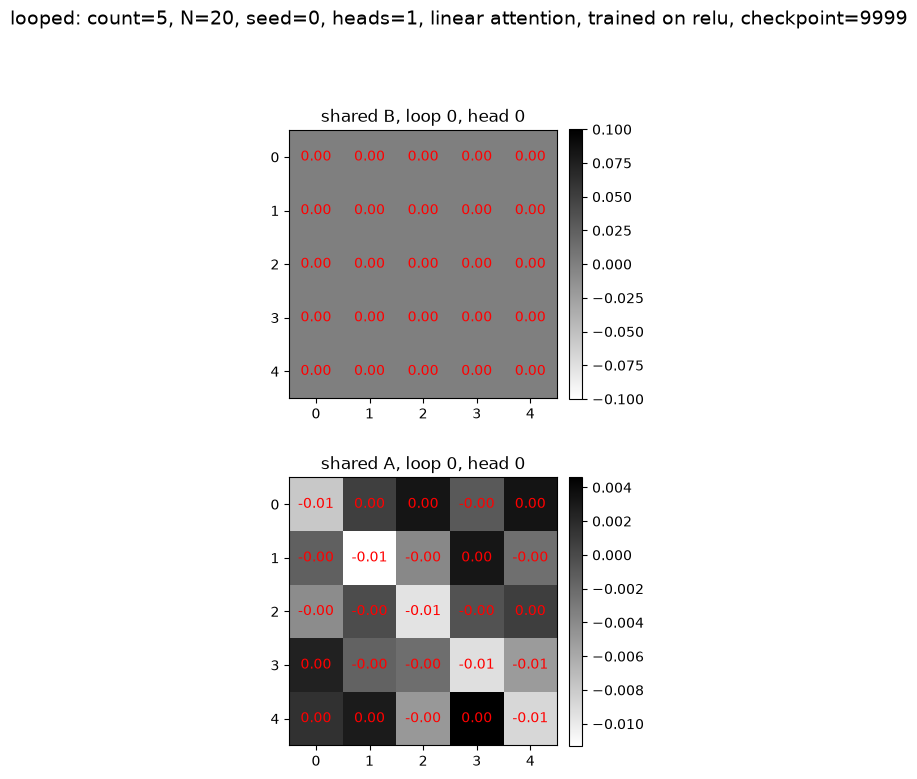

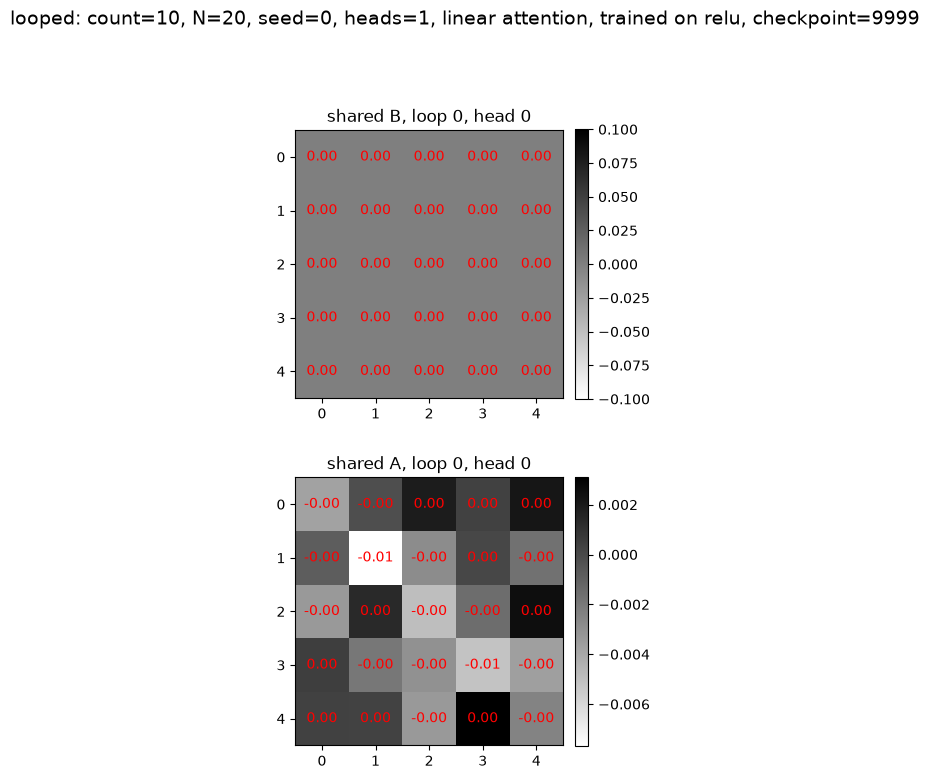

In [8]:
for test_data_mode, loss_dict in nonlinear_loss_dict.items():
    plot_loss_curves(
        loss_dict, loop_counts, model_types, iterations,
        fig_dir=nonlinear_fig_dir,
        filename='nonlinear_data_mode_test_loss.pdf',
        test_data_mode=test_data_mode,
    )
plot_dist_to_identity(
    nonlinear_dist_dict, loop_counts, iterations, fig_dir=nonlinear_fig_dir,
)
plot_parameter_matrices(
    nonlinear_hist_dict, seeds[0], loop_counts, model_types, n_head,
    hist_stride=hist_stride, fig_dir=nonlinear_fig_dir,
)
